In [4]:
!pip install -q -U kagglehub

In [5]:
import kagglehub

path = kagglehub.dataset_download(
    "pranavjha24/car-hacking-dataset",
    output_dir="/content/car_hacking"
)

print("Dataset folder:", path)

Using Colab cache for faster access to the 'car-hacking-dataset' dataset.
Dataset folder: /kaggle/input/car-hacking-dataset


In [127]:
from google.colab import drive
import os

changed all paths to path since it didnt downloaded it to the folder i  set it so i had to redo the code by replacing each value with the new path it was time consuming ngl

#This project uses the Car Hacking:
CAN Intrusion Detection Dataset, a mirror of the dataset created by the Hacking and Countermeasure Research Lab (HCRL) at Korea University. It contains vehicle communication messages recorded during normal operation and attack scenarios. Our goal is to explore these messages and identify patterns that could help an autoencoder detect abnormal traffic.

#Controller Area Network (CAN) allows:
 electronic control units inside a vehicle, such as engine and transmission controllers, to exchange messages. Each message contains an identifier and a small payload of data. Repeated CAN IDs and payloads can occur naturally because vehicle systems send regular updates.
#Files Used in This Notebook:
The files loaded in this notebook differ from the filenames listed in the supplied dataset description:
#File	Contents:
normal_run_data.txt	Normal vehicle traffic
DoS_dataset.csv	Traffic recorded during a denial-of-service attack
Fuzzy_dataset.csv	Traffic recorded during an attack injecting random CAN messages
RPM_dataset.csv	Traffic recorded during RPM spoofing
gear_dataset.csv	Traffic recorded during gear spoofing


The attack files contain both normal and injected attack messages. Although the supplied description mentions replay attacks, no separate replay file is used in this notebook.
##CAN Bus Features
###Feature	Explanation
* Timestamp	The time when a message was recorded. It can help analyze message frequency and the time between messages.
* CAN_ID	A hexadecimal identifier associated with the message’s type and arbitration priority. It is not a unique identifier for each row, so repeated IDs are expected.
* DLC	Data Length Code. In these Classical CAN messages, it specifies the number of payload bytes, from 0 to 8.
* Byte0–Byte7	The message payload, originally represented in hexadecimal. Each byte has a numerical value between 0 and 255. Its specific meaning depends on the vehicle’s message format.
* Label	Identifies normal and attack messages. The notebook uses R for normal messages and T for injected attack messages.


For example,( DLC = 5 means the message contains five payload bytes, Byte0 through Byte4. The remaining byte positions are unused, so empty values in those positions do not necessarily indicate damaged data.)

The supplied description mentions numerical labels 0 and 1, but the files used in this notebook contain R and T. The standalone normal file has no label column, so it is assigned R before combining it with other normal messages.
##Purpose of the EDA
The analysis examines normal and attack proportions, missing values, duplicates, payload distributions, and relationships between features. These findings help guide preprocessing and identify patterns that may support anomaly detection.

The later modeling stage will train an autoencoder on normal traffic and use reconstruction error to identify potentially abnormal messages. Labels will support evaluation and should be excluded from the model’s input features.

In [6]:
import os

for folder, subfolders, files in os.walk(path):
    for file in files:
        print(os.path.join(folder, file))

/kaggle/input/car-hacking-dataset/Fuzzy_dataset.csv
/kaggle/input/car-hacking-dataset/normal_run_data.txt
/kaggle/input/car-hacking-dataset/DoS_dataset.csv
/kaggle/input/car-hacking-dataset/RPM_dataset.csv
/kaggle/input/car-hacking-dataset/gear_dataset.csv


In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [8]:
df_fuzzy=pd.read_csv(f"{path}/Fuzzy_dataset.csv")

In [9]:
df_dos=pd.read_csv(f"{path}/DoS_dataset.csv")

In [10]:
df_rpm=pd.read_csv(f"{path}/RPM_dataset.csv")

In [11]:
df_gear=pd.read_csv(f"{path}/gear_dataset.csv")

##understanding data

In [12]:
df_fuzzy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3838859 entries, 0 to 3838858
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478195721.903877  float64
 1   0545               object 
 2   8                  int64  
 3   d8                 object 
 4   00                 object 
 5   00.1               object 
 6   8a                 object 
 7   00.2               object 
 8   00.3               object 
 9   00.4               object 
 10  00.5               object 
 11  R                  object 
dtypes: float64(1), int64(1), object(10)
memory usage: 351.5+ MB


In [13]:
df_dos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3665770 entries, 0 to 3665769
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478198376.389427  float64
 1   0316               object 
 2   8                  int64  
 3   05                 object 
 4   21                 object 
 5   68                 object 
 6   09                 object 
 7   21.1               object 
 8   21.2               object 
 9   00                 object 
 10  6f                 object 
 11  R                  object 
dtypes: float64(1), int64(1), object(10)
memory usage: 335.6+ MB


In [14]:
df_rpm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4621701 entries, 0 to 4621700
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478191030.045114  float64
 1   0316               object 
 2   8                  int64  
 3   05                 object 
 4   22                 object 
 5   68                 object 
 6   09                 object 
 7   22.1               object 
 8   20                 object 
 9   00                 object 
 10  75                 object 
 11  R                  object 
dtypes: float64(1), int64(1), object(10)
memory usage: 423.1+ MB


In [15]:
df_gear.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4443141 entries, 0 to 4443140
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   1478193190.056566  float64
 1   0140               object 
 2   8                  int64  
 3   00                 object 
 4   00.1               object 
 5   00.2               object 
 6   00.3               object 
 7   10                 object 
 8   29                 object 
 9   2a                 object 
 10  24                 object 
 11  R                  object 
dtypes: float64(1), int64(1), object(10)
memory usage: 406.8+ MB


In [16]:
df_fuzzy

,1478195721.903877,0545,8,d8,00,00.1,8a,00.2,00.3,00.4,00.5,R
0,1.478196e+09,02b0,5,ff,7f,00,05,49,R,NaN,NaN,NaN
1,1.478196e+09,0002,8,00,00,00,00,00,01,07,15,R
2,1.478196e+09,0153,8,00,21,10,ff,00,ff,00,00,R
3,1.478196e+09,0130,8,19,80,00,ff,fe,7f,07,60,R
4,1.478196e+09,0131,8,17,80,00,00,65,7f,07,9f,R
...,...,...,...,...,...,...,...,...,...,...,...,...
3838854,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
3838855,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
3838856,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
3838857,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


In [17]:
df_dos

,1478198376.389427,0316,8,05,21,68,09,21.1,21.2,00,6f,R
0,1.478198e+09,018f,8,fe,5b,00,00,00,3c,00,00,R
1,1.478198e+09,0260,8,19,21,22,30,08,8e,6d,3a,R
2,1.478198e+09,02a0,8,64,00,9a,1d,97,02,bd,00,R
3,1.478198e+09,0329,8,40,bb,7f,14,11,20,00,14,R
4,1.478198e+09,0545,8,d8,00,00,8a,00,00,00,00,R
...,...,...,...,...,...,...,...,...,...,...,...,...
3665765,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
3665766,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
3665767,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
3665768,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


In [18]:
df_rpm

,1478191030.045114,0316,8,05,22,68,09,22.1,20,00,75,R
0,1.478191e+09,018f,8,fe,3b,00,00,00,3c,00,00,R
1,1.478191e+09,0260,8,19,22,22,30,ff,8f,6e,3f,R
2,1.478191e+09,02a0,8,60,00,83,1d,96,02,bd,00,R
3,1.478191e+09,0329,8,dc,b8,7e,14,11,20,00,14,R
4,1.478191e+09,0545,8,d8,00,00,83,00,00,00,00,R
...,...,...,...,...,...,...,...,...,...,...,...,...
4621696,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
4621697,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
4621698,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
4621699,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


In [19]:
df_gear

,1478193190.056566,0140,8,00,00.1,00.2,00.3,10,29,2a,24,R
0,1.478193e+09,02c0,8,15,00,00,00,00,00,00,00,R
1,1.478193e+09,0350,8,05,20,44,68,77,00,00,7e,R
2,1.478193e+09,0370,8,00,20,00,00,00,00,00,00,R
3,1.478193e+09,043f,8,10,40,60,ff,78,c4,08,00,R
4,1.478193e+09,0440,8,ff,00,00,00,ff,c4,08,00,R
...,...,...,...,...,...,...,...,...,...,...,...,...
4443136,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
4443137,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
4443138,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
4443139,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


it seems it put the first row as the header to fix will do this instead

In [20]:
df_fuzzy = pd.read_csv(f"{path}/Fuzzy_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [21]:
df_dos=pd.read_csv(f"{path}/DoS_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [22]:
df_rpm=pd.read_csv(f"{path}/RPM_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [23]:
df_gear=pd.read_csv(f"{path}/gear_dataset.csv",header=None,names=["Timestamp","CAN_ID","DLC","Byte0", "Byte1", "Byte2", "Byte3","Byte4", "Byte5", "Byte6", "Byte7","Label"])

In [24]:
df_fuzzy.describe()

,Timestamp,DLC
count,3.838860e+06,3.838860e+06
mean,1.478198e+09,7.904490e+00
std,1.837432e+03,6.622847e-01
min,1.478196e+09,2.000000e+00
25%,1.478196e+09,8.000000e+00
50%,1.478197e+09,8.000000e+00
75%,1.478198e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [25]:
df_dos.describe()

,Timestamp,DLC
count,3.665771e+06,3.665771e+06
mean,1.478200e+09,7.948953e+00
std,8.471851e+02,5.510703e-01
min,1.478198e+09,2.000000e+00
25%,1.478199e+09,8.000000e+00
50%,1.478200e+09,8.000000e+00
75%,1.478201e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [26]:
df_rpm.describe()

,Timestamp,DLC
count,4.621702e+06,4.621702e+06
mean,1.478194e+09,7.946155e+00
std,3.565417e+03,5.658369e-01
min,1.478191e+09,2.000000e+00
25%,1.478192e+09,8.000000e+00
50%,1.478192e+09,8.000000e+00
75%,1.478193e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [27]:
df_gear.describe()

,Timestamp,DLC
count,4.443142e+06,4.443142e+06
mean,1.478196e+09,7.945761e+00
std,2.771755e+03,5.678821e-01
min,1.478193e+09,2.000000e+00
25%,1.478194e+09,8.000000e+00
50%,1.478194e+09,8.000000e+00
75%,1.478195e+09,8.000000e+00
max,1.478201e+09,8.000000e+00


In [28]:
df_fuzzy

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478196e+09,0545,8,d8,00,00,8a,00,00,00,00,R
1,1.478196e+09,02b0,5,ff,7f,00,05,49,R,NaN,NaN,NaN
2,1.478196e+09,0002,8,00,00,00,00,00,01,07,15,R
3,1.478196e+09,0153,8,00,21,10,ff,00,ff,00,00,R
4,1.478196e+09,0130,8,19,80,00,ff,fe,7f,07,60,R
...,...,...,...,...,...,...,...,...,...,...,...,...
3838855,1.478201e+09,018f,8,fe,59,00,00,00,41,00,00,R
3838856,1.478201e+09,0260,8,18,21,21,30,08,8f,6d,19,R
3838857,1.478201e+09,02a0,8,24,00,9a,1d,97,02,bd,00,R
3838858,1.478201e+09,0329,8,dc,b7,7f,14,11,20,00,14,R


checking for missing or invalid values

In [29]:
df_fuzzy.isnull().sum()

,0
Timestamp,0
CAN_ID,0
DLC,0
Byte0,0
Byte1,0
Byte2,0
Byte3,34382
Byte4,34382
Byte5,34382
Byte6,87833


In [30]:
df_dos.isnull().sum()

,0
Timestamp,0
CAN_ID,0
DLC,0
Byte0,0
Byte1,0
Byte2,0
Byte3,31188
Byte4,31188
Byte5,31188
Byte6,31188


In [31]:
df_rpm.isnull().sum()

,0
Timestamp,0
CAN_ID,0
DLC,0
Byte0,0
Byte1,0
Byte2,0
Byte3,41476
Byte4,41476
Byte5,41476
Byte6,41476


In [32]:
df_gear.isnull().sum()

,0
Timestamp,0
CAN_ID,0
DLC,0
Byte0,0
Byte1,0
Byte2,0
Byte3,40165
Byte4,40165
Byte5,40165
Byte6,40165


there seems to be some missing values but well check thier precentage then will conclude the right procedure

In [33]:
df_fuzzy.duplicated().sum()

np.int64(0)

In [34]:
df_dos.duplicated().sum()

np.int64(0)

In [35]:
df_rpm.duplicated().sum()

np.int64(0)

In [36]:
df_gear.duplicated().sum()

np.int64(0)

there doesnt seem to be any duplicates of data

##Cleaning

In [37]:
df_fuzzy.isnull().mean()

,0
Timestamp,0.000000
CAN_ID,0.000000
DLC,0.000000
Byte0,0.000000
Byte1,0.000000
Byte2,0.000000
Byte3,0.008956
Byte4,0.008956
Byte5,0.008956
Byte6,0.022880


below 5% removed

In [38]:
byte_columns = [
    "Byte0", "Byte1", "Byte2", "Byte3",
    "Byte4", "Byte5", "Byte6", "Byte7"
]


In [39]:
for data in [df_fuzzy, df_dos, df_rpm, df_gear]:
    for dlc, column in enumerate(byte_columns):
        shifted = (
            data["DLC"].eq(dlc)
            & data["Label"].isna()
            & data[column].isin(["R", "T"])
        )

        data.loc[shifted, "Label"] = data.loc[shifted, column]
        data.loc[shifted, column] = np.nan


In [40]:
byte_count = df_fuzzy[byte_columns].notna().sum(axis=1)

In [41]:
valid = (
    df_fuzzy["Timestamp"].notna()
    & df_fuzzy["CAN_ID"].notna()
    & df_fuzzy["DLC"].isin(range(9))
    & byte_count.eq(df_fuzzy["DLC"])
    & df_fuzzy["Label"].notna()
)


In [42]:
#df_fuzzy=df_fuzzy.dropna(axis=0)

as you can see not only is the values are missing but its also unordered correctly and since the % is little im gonna drop it like how i stated earliar (the reason i didnt drop the na values is that dlc data is the bytes numbers where it indicates when what bytes are used and what isnt)

In [43]:
df_fuzzy=df_fuzzy[valid]

In [44]:
df_dos.isnull().mean()

,0
Timestamp,0.000000
CAN_ID,0.000000
DLC,0.000000
Byte0,0.000000
Byte1,0.000000
Byte2,0.008508
Byte3,0.008508
Byte4,0.008508
Byte5,0.008508
Byte6,0.008508


checking before dropping rows like how we did in fuzzy

In [45]:
#df_dos=df_dos.dropna(axis=0)
byte_count = df_dos[byte_columns].notna().sum(axis=1)
valid = (
    df_dos["Timestamp"].notna()
    & df_dos["CAN_ID"].notna()
    & df_dos["DLC"].isin(range(9))
    & byte_count.eq(df_dos["DLC"])
    & df_dos["Label"].notna()
)



In [46]:
df_dos=df_dos[valid]

checking before dropping rows like how we did in fuzzy

In [47]:
#df_rpm=df_rpm.dropna(axis=0)

In [48]:
byte_count = df_rpm[byte_columns].notna().sum(axis=1)
valid = (
    df_rpm["Timestamp"].notna()
    & df_rpm["CAN_ID"].notna()
    & df_rpm["DLC"].isin(range(9))
    & byte_count.eq(df_rpm["DLC"])
    & df_rpm["Label"].notna()
)



In [49]:
df_rpm=df_rpm[valid]

In [50]:
df_gear.isnull().mean()

,0
Timestamp,0.00000
CAN_ID,0.00000
DLC,0.00000
Byte0,0.00000
Byte1,0.00000
Byte2,0.00904
Byte3,0.00904
Byte4,0.00904
Byte5,0.00904
Byte6,0.00904


checking before dropping rows like how we did in fuzzy

In [51]:
#df_gear=df_gear.dropna(axis=0)

In [52]:
byte_count = df_gear[byte_columns].notna().sum(axis=1)
valid = (
    df_gear["Timestamp"].notna()
    & df_gear["CAN_ID"].notna()
    & df_gear["DLC"].isin(range(9))
    & byte_count.eq(df_gear["DLC"])
    & df_gear["Label"].notna()
)



In [53]:
df_gear=df_gear[valid]

In [54]:
df_fuzzy.shape

(3838860, 12)

In [55]:
df_dos.shape

(3665771, 12)

In [56]:
df_rpm.shape

(4621702, 12)

In [57]:
df_gear.shape

(4443142, 12)

In [58]:

for column in byte_columns:
    df_fuzzy[column] = df_fuzzy[column].map(
        lambda value: int(value, 16) if isinstance(value, str) else value
    )

In [59]:
df_fuzzy.head()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478196e+09,0545,8,216,0,0.0,138.0,0.0,0.0,0.0,0.0,R
1,1.478196e+09,02b0,5,255,127,0.0,5.0,73.0,NaN,NaN,NaN,R
2,1.478196e+09,0002,8,0,0,0.0,0.0,0.0,1.0,7.0,21.0,R
3,1.478196e+09,0153,8,0,33,16.0,255.0,0.0,255.0,0.0,0.0,R
4,1.478196e+09,0130,8,25,128,0.0,255.0,254.0,127.0,7.0,96.0,R


In [60]:
df_fuzzy.tail()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
3838855,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
3838856,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
3838857,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
3838858,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
3838859,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


In [61]:
for column in byte_columns:
    df_dos[column] = df_dos[column].map(
        lambda value: int(value, 16) if isinstance(value, str) else value
    )

In [62]:
df_dos.head()


,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478198e+09,0316,8,5,33,104.0,9.0,33.0,33.0,0.0,111.0,R
1,1.478198e+09,018f,8,254,91,0.0,0.0,0.0,60.0,0.0,0.0,R
2,1.478198e+09,0260,8,25,33,34.0,48.0,8.0,142.0,109.0,58.0,R
3,1.478198e+09,02a0,8,100,0,154.0,29.0,151.0,2.0,189.0,0.0,R
4,1.478198e+09,0329,8,64,187,127.0,20.0,17.0,32.0,0.0,20.0,R


In [63]:
df_dos.tail()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
3665766,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
3665767,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
3665768,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
3665769,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
3665770,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


In [64]:
for column in byte_columns:
    df_rpm[column] = df_rpm[column].map(
        lambda value: int(value, 16) if isinstance(value, str) else value
    )

In [65]:
df_rpm.head()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478191e+09,0316,8,5,34,104.0,9.0,34.0,32.0,0.0,117.0,R
1,1.478191e+09,018f,8,254,59,0.0,0.0,0.0,60.0,0.0,0.0,R
2,1.478191e+09,0260,8,25,34,34.0,48.0,255.0,143.0,110.0,63.0,R
3,1.478191e+09,02a0,8,96,0,131.0,29.0,150.0,2.0,189.0,0.0,R
4,1.478191e+09,0329,8,220,184,126.0,20.0,17.0,32.0,0.0,20.0,R


In [66]:
df_rpm.tail()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
4621697,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
4621698,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
4621699,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
4621700,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
4621701,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


In [67]:
for column in byte_columns:
    df_gear[column] = df_gear[column].map(
        lambda value: int(value, 16) if isinstance(value, str) else value
    )

In [68]:
df_gear.head()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.478193e+09,0140,8,0,0,0.0,0.0,16.0,41.0,42.0,36.0,R
1,1.478193e+09,02c0,8,21,0,0.0,0.0,0.0,0.0,0.0,0.0,R
2,1.478193e+09,0350,8,5,32,68.0,104.0,119.0,0.0,0.0,126.0,R
3,1.478193e+09,0370,8,0,32,0.0,0.0,0.0,0.0,0.0,0.0,R
4,1.478193e+09,043f,8,16,64,96.0,255.0,120.0,196.0,8.0,0.0,R


In [69]:
df_gear.tail()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
4443137,1.478201e+09,018f,8,254,89,0.0,0.0,0.0,65.0,0.0,0.0,R
4443138,1.478201e+09,0260,8,24,33,33.0,48.0,8.0,143.0,109.0,25.0,R
4443139,1.478201e+09,02a0,8,36,0,154.0,29.0,151.0,2.0,189.0,0.0,R
4443140,1.478201e+09,0329,8,220,183,127.0,20.0,17.0,32.0,0.0,20.0,R
4443141,1.478201e+09,0545,8,216,0,0.0,139.0,0.0,0.0,0.0,0.0,R


## now its time to see the safe/normal data

In [70]:
df=pd.read_csv(f"{path}/normal_run_data.txt")

In [71]:
df

,Timestamp: 1479121434.850202 ID: 0350 000 DLC: 8 05 28 84 66 6d 00 00 a2
0,Timestamp: 1479121434.850423 ID: 02c0 ...
1,Timestamp: 1479121434.850977 ID: 0430 ...
2,Timestamp: 1479121434.851215 ID: 04b1 ...
3,Timestamp: 1479121434.851463 ID: 01f1 ...
4,Timestamp: 1479121434.851711 ID: 0153 ...
...,...
988866,Timestamp: 1479121941.286087 ID: 0316 ...
988867,Timestamp: 1479121941.286310 ID: 018f ...
988868,Timestamp: 1479121941.286533 ID: 0260 ...
988869,Timestamp: 1479121941.286773 ID: 02a0 ...


In [72]:
df = pd.read_csv(f"{path}/normal_run_data.txt",sep=r"\s+",header=None,)

In [73]:
df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Timestamp:,1.479121e+09,ID:,0350,0.0,DLC:,8.0,05,28,84,66,6d,00,00,a2
1,Timestamp:,1.479121e+09,ID:,02c0,0.0,DLC:,8.0,14,00,00,00,00,00,00,00
2,Timestamp:,1.479121e+09,ID:,0430,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
3,Timestamp:,1.479121e+09,ID:,04b1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
4,Timestamp:,1.479121e+09,ID:,01f1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
988867,Timestamp:,1.479122e+09,ID:,0316,0.0,DLC:,8.0,05,38,10,0c,38,28,01,7a
988868,Timestamp:,1.479122e+09,ID:,018f,0.0,DLC:,8.0,fe,31,00,00,00,4b,00,00
988869,Timestamp:,1.479122e+09,ID:,0260,0.0,DLC:,8.0,32,38,39,30,ff,93,59,1c
988870,Timestamp:,1.479122e+09,ID:,02a0,0.0,DLC:,8.0,20,00,75,1d,01,04,dd,00


In [74]:
df.columns = [
    "Timestamp_tag", "Timestamp", "ID_tag", "CAN_ID", "Extra",
    "DLC_tag", "DLC",
    "Byte0", "Byte1", "Byte2", "Byte3",
    "Byte4", "Byte5", "Byte6", "Byte7"
]

In [75]:
df

,Timestamp_tag,Timestamp,ID_tag,CAN_ID,Extra,DLC_tag,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7
0,Timestamp:,1.479121e+09,ID:,0350,0.0,DLC:,8.0,05,28,84,66,6d,00,00,a2
1,Timestamp:,1.479121e+09,ID:,02c0,0.0,DLC:,8.0,14,00,00,00,00,00,00,00
2,Timestamp:,1.479121e+09,ID:,0430,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
3,Timestamp:,1.479121e+09,ID:,04b1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
4,Timestamp:,1.479121e+09,ID:,01f1,0.0,DLC:,8.0,00,00,00,00,00,00,00,00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
988867,Timestamp:,1.479122e+09,ID:,0316,0.0,DLC:,8.0,05,38,10,0c,38,28,01,7a
988868,Timestamp:,1.479122e+09,ID:,018f,0.0,DLC:,8.0,fe,31,00,00,00,4b,00,00
988869,Timestamp:,1.479122e+09,ID:,0260,0.0,DLC:,8.0,32,38,39,30,ff,93,59,1c
988870,Timestamp:,1.479122e+09,ID:,02a0,0.0,DLC:,8.0,20,00,75,1d,01,04,dd,00


Timestamp, CAN ID, Data Length Code (DLC), Data (hexadecimal payload).

Label (0 for normal, 1 for attack).

In [76]:
drop=["Timestamp_tag","ID_tag","DLC_tag","Extra"]
df=df.drop(columns=drop,axis=1)

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 988872 entries, 0 to 988871
Data columns (total 11 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Timestamp  988872 non-null  float64
 1   CAN_ID     988871 non-null  object 
 2   DLC        988871 non-null  float64
 3   Byte0      988871 non-null  object 
 4   Byte1      988871 non-null  object 
 5   Byte2      978742 non-null  object 
 6   Byte3      978742 non-null  object 
 7   Byte4      978742 non-null  object 
 8   Byte5      928136 non-null  object 
 9   Byte6      928136 non-null  object 
 10  Byte7      928136 non-null  object 
dtypes: float64(2), object(9)
memory usage: 83.0+ MB


In [78]:
df.describe()

,Timestamp,DLC
count,9.888720e+05,988871.000000
mean,1.479122e+09,7.785015
std,1.461964e+02,0.884935
min,1.479121e+09,2.000000
25%,1.479122e+09,8.000000
50%,1.479122e+09,8.000000
75%,1.479122e+09,8.000000
max,1.479122e+09,8.000000


In [79]:
df.shape

(988872, 11)

In [80]:
df.isnull().sum()

,0
Timestamp,0
CAN_ID,1
DLC,1
Byte0,1
Byte1,1
Byte2,10130
Byte3,10130
Byte4,10130
Byte5,60736
Byte6,60736


In [81]:
df.duplicated().sum()

np.int64(0)

no duplicates

In [82]:
df.isnull().mean()

,0
Timestamp,0.000000
CAN_ID,0.000001
DLC,0.000001
Byte0,0.000001
Byte1,0.000001
Byte2,0.010244
Byte3,0.010244
Byte4,0.010244
Byte5,0.061419
Byte6,0.061419


below 5% but we cant drop because Dlc relys on to the bytes what i mean is that dlc could be 4 meaning only 4 bytes are filled which indicates info

In [83]:
#df=df.dropna(axis=0)

In [84]:
df.shape

(988872, 11)

In [85]:
df["DLC"] = pd.to_numeric(df["DLC"], errors="coerce")

In [86]:
df['Timestamp']=pd.to_numeric(df['Timestamp'],errors="coerce")

In [87]:
byte_count = df[byte_columns].notna().sum(axis=1)

so to check if the bytes are corosponding to the dlc will check all not nulls and see if they are valid and for the bytes we check if dlc has atleast the required numbers then its valid otherwise not

In [88]:
valid = (
    df["Timestamp"].notna()
    & df["CAN_ID"].notna()
    & df["DLC"].isin(range(9))
    & byte_count.eq(df["DLC"])

)

invalid = df[~valid].copy()

In [89]:
invalid

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7
988871,1.479122e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [90]:
df=df[valid]
df

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7
0,1.479121e+09,0350,8.0,05,28,84,66,6d,00,00,a2
1,1.479121e+09,02c0,8.0,14,00,00,00,00,00,00,00
2,1.479121e+09,0430,8.0,00,00,00,00,00,00,00,00
3,1.479121e+09,04b1,8.0,00,00,00,00,00,00,00,00
4,1.479121e+09,01f1,8.0,00,00,00,00,00,00,00,00
...,...,...,...,...,...,...,...,...,...,...,...
988866,1.479122e+09,02b0,5.0,ac,05,0c,07,7f,NaN,NaN,NaN
988867,1.479122e+09,0316,8.0,05,38,10,0c,38,28,01,7a
988868,1.479122e+09,018f,8.0,fe,31,00,00,00,4b,00,00
988869,1.479122e+09,0260,8.0,32,38,39,30,ff,93,59,1c


In [92]:
for column in byte_columns:
    df[column] = df[column].map(
        lambda value: int(value, 16) if isinstance(value, str) else value
    )

df["Label"] = "R"

In [93]:
df

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.479121e+09,0350,8.0,5,40,132.0,102.0,109.0,0.0,0.0,162.0,R
1,1.479121e+09,02c0,8.0,20,0,0.0,0.0,0.0,0.0,0.0,0.0,R
2,1.479121e+09,0430,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
3,1.479121e+09,04b1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
4,1.479121e+09,01f1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
...,...,...,...,...,...,...,...,...,...,...,...,...
988866,1.479122e+09,02b0,5.0,172,5,12.0,7.0,127.0,NaN,NaN,NaN,R
988867,1.479122e+09,0316,8.0,5,56,16.0,12.0,56.0,40.0,1.0,122.0,R
988868,1.479122e+09,018f,8.0,254,49,0.0,0.0,0.0,75.0,0.0,0.0,R
988869,1.479122e+09,0260,8.0,50,56,57.0,48.0,255.0,147.0,89.0,28.0,R


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 988871 entries, 0 to 988870
Data columns (total 12 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Timestamp  988871 non-null  float64
 1   CAN_ID     988871 non-null  object 
 2   DLC        988871 non-null  float64
 3   Byte0      988871 non-null  int64  
 4   Byte1      988871 non-null  int64  
 5   Byte2      978742 non-null  float64
 6   Byte3      978742 non-null  float64
 7   Byte4      978742 non-null  float64
 8   Byte5      928136 non-null  float64
 9   Byte6      928136 non-null  float64
 10  Byte7      928136 non-null  float64
 11  Label      988871 non-null  object 
dtypes: float64(8), int64(2), object(2)
memory usage: 98.1+ MB


In [95]:
df.head()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
0,1.479121e+09,0350,8.0,5,40,132.0,102.0,109.0,0.0,0.0,162.0,R
1,1.479121e+09,02c0,8.0,20,0,0.0,0.0,0.0,0.0,0.0,0.0,R
2,1.479121e+09,0430,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
3,1.479121e+09,04b1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R
4,1.479121e+09,01f1,8.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,R


In [96]:
df.tail()

,Timestamp,CAN_ID,DLC,Byte0,Byte1,Byte2,Byte3,Byte4,Byte5,Byte6,Byte7,Label
988866,1.479122e+09,02b0,5.0,172,5,12.0,7.0,127.0,NaN,NaN,NaN,R
988867,1.479122e+09,0316,8.0,5,56,16.0,12.0,56.0,40.0,1.0,122.0,R
988868,1.479122e+09,018f,8.0,254,49,0.0,0.0,0.0,75.0,0.0,0.0,R
988869,1.479122e+09,0260,8.0,50,56,57.0,48.0,255.0,147.0,89.0,28.0,R
988870,1.479122e+09,02a0,8.0,32,0,117.0,29.0,1.0,4.0,221.0,0.0,R


##Univariantes

###for fuzzy

<Axes: xlabel='count', ylabel='Label'>

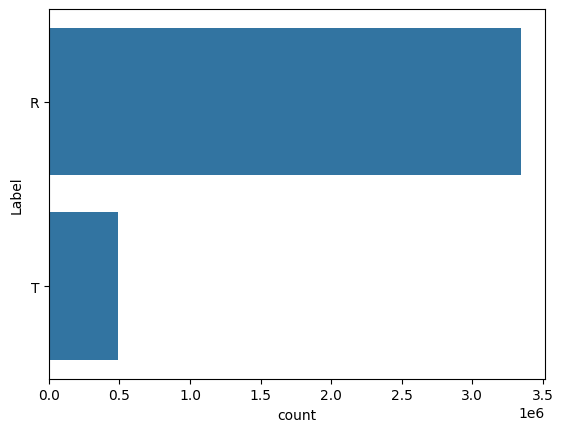

In [97]:
sns.countplot(df_fuzzy["Label"])

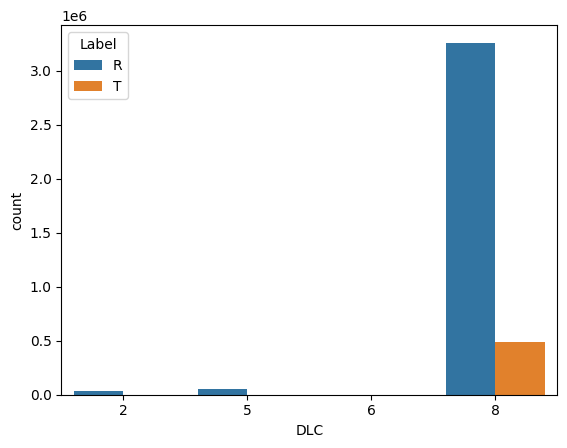

In [98]:
sns.countplot(data=df_fuzzy, x="DLC", hue="Label")
plt.show()

In [99]:
df_fuzzy["Label"].value_counts(normalize=True) * 100

,proportion
Label,
R,87.187681
T,12.812319


an imbalance class , this indicates that there are more normal cases than abnormal that means accuracy wouldnt be much of help. R=safe ,T=attacks

In [100]:
df_fuzzy.columns

Index(['Timestamp', 'CAN_ID', 'DLC', 'Byte0', 'Byte1', 'Byte2', 'Byte3',
       'Byte4', 'Byte5', 'Byte6', 'Byte7', 'Label'],
      dtype='object')

<Axes: xlabel='DLC', ylabel='Count'>

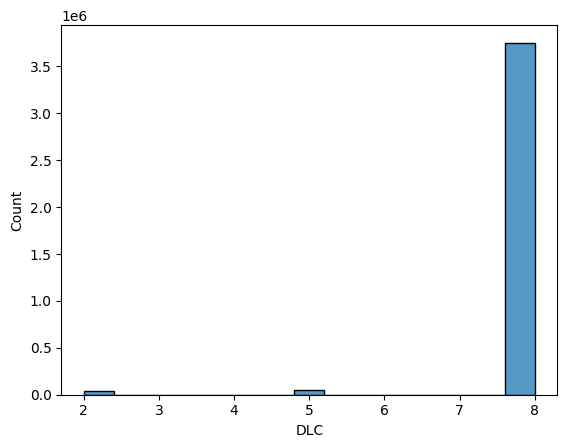

In [101]:
sns.histplot(df_fuzzy,x="DLC",bins=15)

<Axes: xlabel='DLC'>

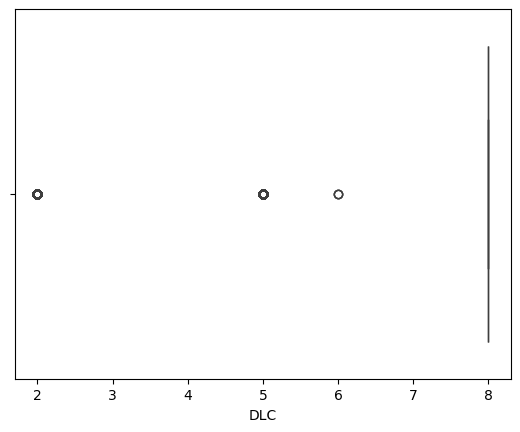

In [102]:
sns.boxplot(data=df_fuzzy,x="DLC")

as we can observe that there are outliers however they are essintial and useful for determining the message sent.   

### for dos

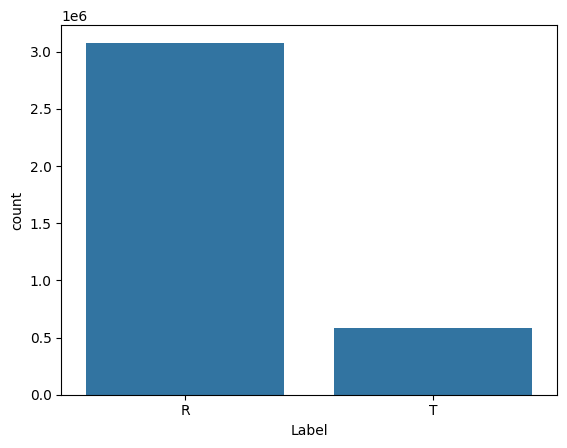

In [103]:
sns.countplot(data=df_dos, x="Label")
plt.show()

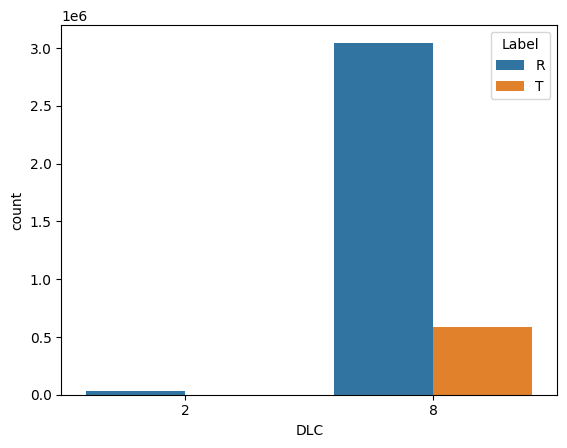

In [104]:
sns.countplot(data=df_dos, x="DLC", hue="Label")
plt.show()

In [105]:
df_dos["Label"].value_counts(normalize=True) * 100

,proportion
Label,
R,83.972785
T,16.027215


Similar estimation as fuzzy

<Axes: xlabel='DLC', ylabel='Count'>

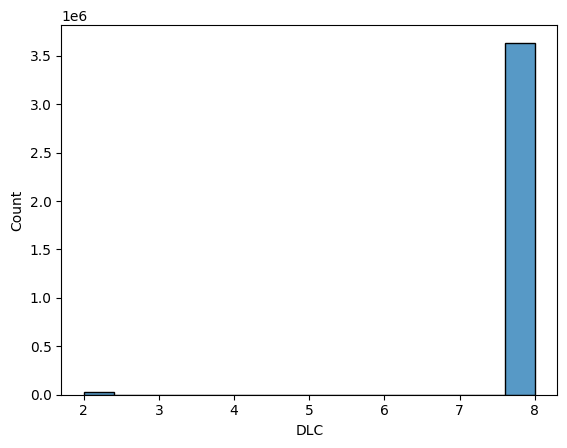

In [106]:
sns.histplot(df_dos["DLC"],bins=15)

In [107]:
df_dos["DLC"].value_counts()

,count
DLC,
8,3634583
2,31188


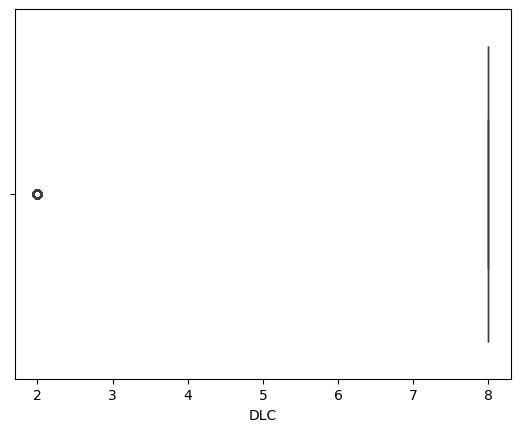

In [108]:
sns.boxplot(data=df_dos, x="DLC")
plt.show()

Similar estimation as fuzzy

### for rpm

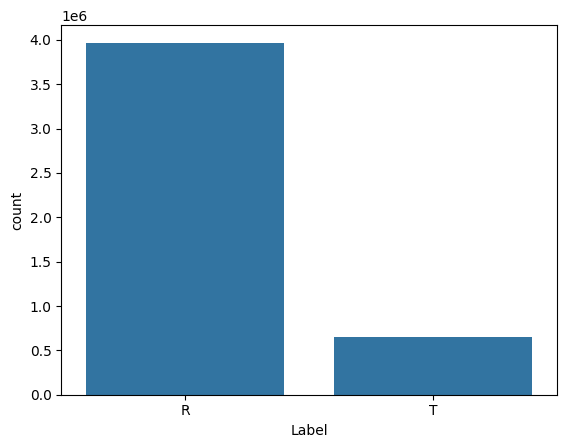

In [109]:
sns.countplot(data=df_rpm, x="Label")
plt.show()

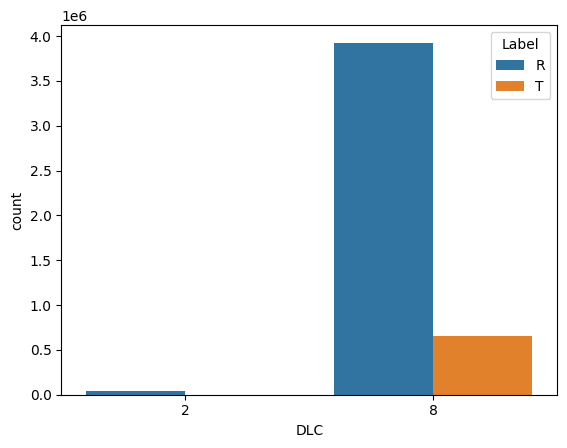

In [110]:
sns.countplot(data=df_rpm, x="DLC", hue="Label")
plt.show()

In [111]:
df_rpm["Label"].value_counts(normalize=True) * 100

,proportion
Label,
R,85.82996
T,14.17004


Similar estimation as fuzzy

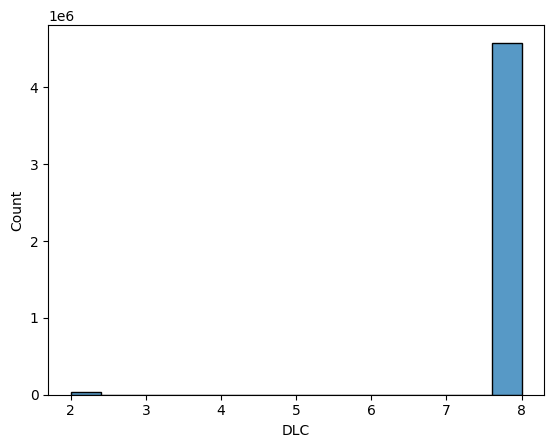

In [112]:
sns.histplot(data=df_rpm, x="DLC", bins=15)
plt.show()

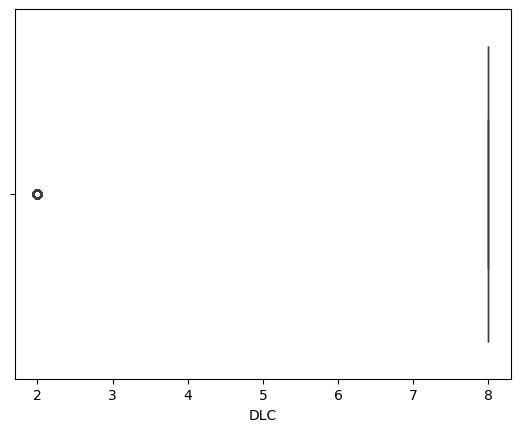

In [113]:
sns.boxplot(data=df_rpm, x="DLC")
plt.show()

Similar estimation as fuzzy

### for gear

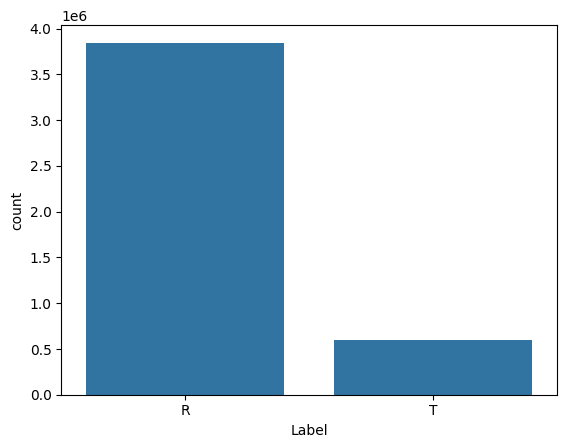

In [114]:
sns.countplot(data=df_gear, x="Label")
plt.show()

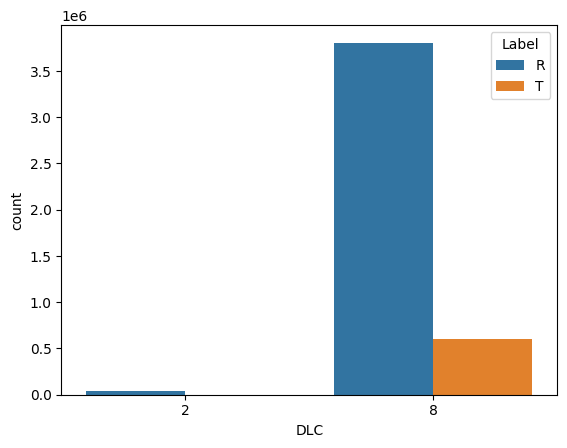

In [115]:
sns.countplot(data=df_gear, x="DLC", hue="Label")
plt.show()

In [116]:
df_gear["Label"].value_counts(normalize=True) * 100

,proportion
Label,
R,86.557891
T,13.442109


Similar estimation as fuzzy

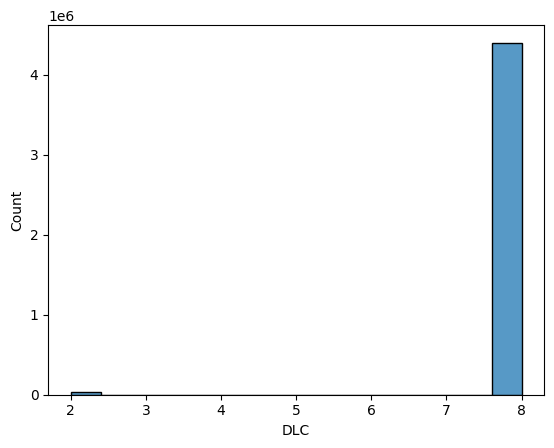

In [117]:
sns.histplot(data=df_gear, x="DLC", bins=15)
plt.show()

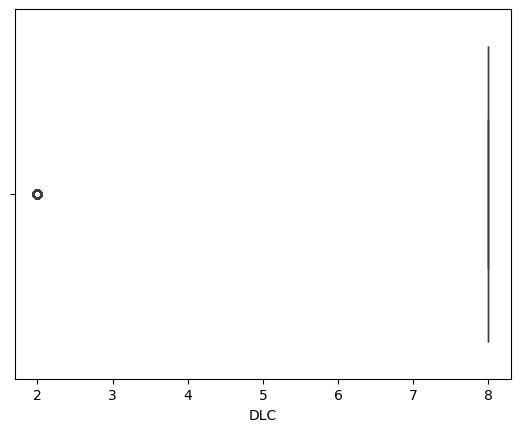

In [118]:
sns.boxplot(data=df_gear, x="DLC")
plt.show()

Similar estimation as fuzzy

##Bivariantes

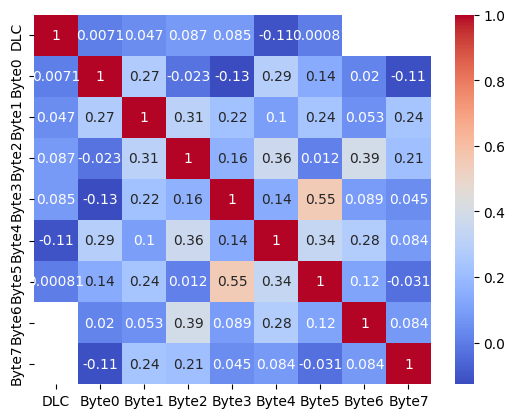

In [119]:
sns.heatmap(
    df_fuzzy[["DLC"] + byte_columns].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.show()

this wont tell much since each values correlation is a Byte however Most byte correlations are weak. Byte 4 is the most strongest out of the negative weak correlations

### for dos

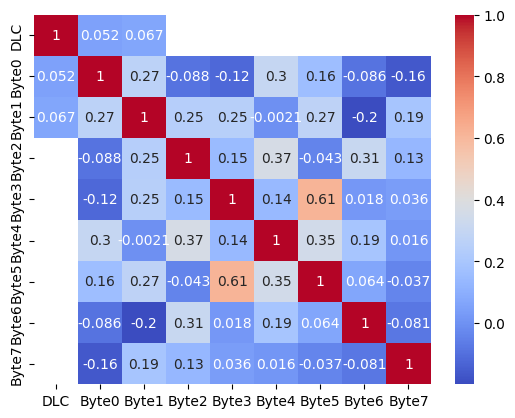

In [120]:
sns.heatmap(df_dos[["DLC"] + byte_columns].corr(), annot=True, cmap="coolwarm")
plt.show()

in this we see that DLC has really small correlations within Byte 0 and 1 meaning they are the most dominant bytes used for said attacks however we cannot be certain(requires further studying)

### for rpm

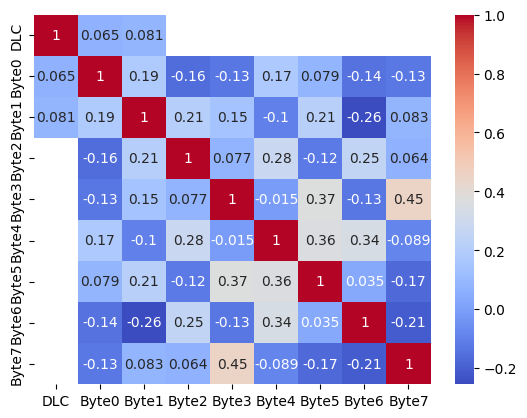

In [121]:
sns.heatmap(df_rpm[["DLC"] + byte_columns].corr(), annot=True, cmap="coolwarm")
plt.show()

byte 0 and 1 have a weak negative correlation around 0.065 and 0.081. No byte pair shows a very strong linear relationship.

### for gear

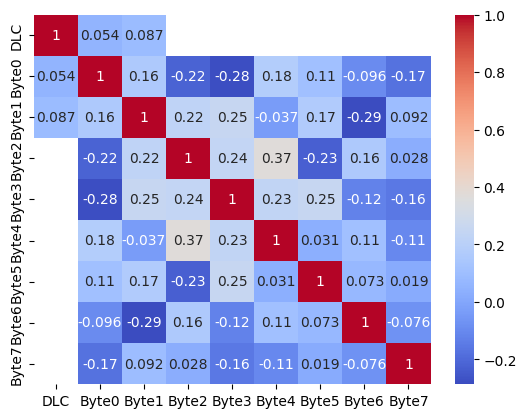

In [122]:
sns.heatmap(df_gear[["DLC"] + byte_columns].corr(), annot=True, cmap="coolwarm")
plt.show()

Byte 0 and 1 have the weak negative correlation around 0.054 and 0.087 meaning their values tend to move in opposite directions.

this suggest that Comparing heatmaps for normal and attack messages separately could reveal differences hidden when both groups are combined.

In [123]:
comp= df_fuzzy.groupby("Label")[byte_columns].mean().T
comp.columns.name = "Label"

comp

Label,R,T
Byte0,61.389985,127.375576
Byte1,44.859566,127.637741
Byte2,36.946443,127.484756
Byte3,64.068773,127.309590
Byte4,48.260603,127.362393
Byte5,69.020602,127.681824
Byte6,26.184431,127.356806
Byte7,48.507336,127.351622


we cant determine which byte is targeted hence all could be possible

In [124]:
comp= df_dos.groupby("Label")[byte_columns].mean().T
comp.columns.name = "Label"

comp

Label,R,T
Byte0,60.174958,0.0
Byte1,44.567195,0.0
Byte2,36.543299,0.0
Byte3,65.003091,0.0
Byte4,46.782640,0.0
Byte5,67.614578,0.0
Byte6,26.207661,0.0
Byte7,48.774627,0.0


no attacks are visible hence safe

In [125]:
comp= df_rpm.groupby("Label")[byte_columns].mean().T
comp.columns.name = "Label"

comp

Label,R,T
Byte0,58.844990,69.0
Byte1,42.826497,41.0
Byte2,35.565130,36.0
Byte3,64.304694,255.0
Byte4,56.114639,41.0
Byte5,66.705234,36.0
Byte6,26.446955,0.0
Byte7,45.409892,255.0


as we can see that byte 3 is the most attacks hence targeted since it has a great difference

In [126]:
comp= df_gear.groupby("Label")[byte_columns].mean().T
comp.columns.name = "Label"

comp

Label,R,T
Byte0,59.585722,1.0
Byte1,43.232545,69.0
Byte2,38.468194,96.0
Byte3,64.136892,255.0
Byte4,45.636446,107.0
Byte5,61.466407,0.0
Byte6,26.089265,0.0
Byte7,45.355902,0.0


though keep in mind that the outputs dont tell us for certain that the bytes are the target since its an avg and hypothisis only

In [128]:
drive.mount("/content/drive")

folder = "/content/drive/MyDrive/CAN_Cleaned"
os.makedirs(folder, exist_ok=True)

datasets = {
    "normal": df,
    "fuzzy": df_fuzzy,
    "dos": df_dos,
    "rpm": df_rpm,
    "gear": df_gear
}

for name, data in datasets.items():
    assert data["Label"].isin(["R", "T"]).all(), f"Check Label in {name}"

    for position, column in enumerate(byte_columns):
        assert data[column].notna().eq(data["DLC"] > position).all(), (
            f"Check {column} and DLC in {name}"
        )

    data.to_parquet(f"{folder}/{name}.parquet", index=False)
    print(f"Saved {name}.parquet | {len(data):,} rows")

Mounted at /content/drive
Saved normal.parquet | 988,871 rows
Saved fuzzy.parquet | 3,838,860 rows
Saved dos.parquet | 3,665,771 rows
Saved rpm.parquet | 4,621,702 rows
Saved gear.parquet | 4,443,142 rows


saving the datasets

###EDA Conclusion
From the EDA we can see that normal messages are more common than attacks in all four datasets.so accuracy alone wouldnt be enough to evaluate the model.
We checked missing values and duplicates.and how many bytes are used
We separated normal and abnormal messages using their labels so we have normal traffic as a baseline to compare attacks with. We compared their average byte values.
The heatmaps show mostly weak to moderate relationships between the bytes. The average comparisons showed differences between normal and attack messages that could help with detection, but they dont confirm which bytes are targeted.
most remaining messages in the attack datasets have DLC of 8 after cleaning. which indicates that the class is imbalnced.